# 2. Exploratory Data Analysis and Preprocessing

**Goal**: Download both datasets, inspect class distributions, visualise sample images, and assess image quality across domains (Spain vs. African countries).

**Datasets**:
- FetalPlanes DB (Spain): 12,400 images, 6 classes, 1792 patients - [Zenodo 3904280](https://zenodo.org/record/3904280)
- African Multi-centre: ~550 images, 5 African countries - [Zenodo 7540448](https://doi.org/10.5281/zenodo.7540448)


In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/OBS_Ultrasound_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("OBS_Ultrasound_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# Download datasets
!bash scripts/download_data.sh

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from PIL import Image
import cv2

from src.data import CLASSES
from src.data.preprocessing import compute_image_quality_score
from src.data.preprocessing import CLAHEPreprocessor, compute_image_quality_score, build_preprocessing_pipeline
from src.utils import set_seed

set_seed(42)
sns.set_style("whitegrid")
CLASSES_DISPLAY = [c.replace("_", " ").title() for c in CLASSES]


## 1. Class Distribution - Spanish FetalPlanes DB

In [6]:
CLASSES

['abdomen', 'brain', 'femur', 'other']

In [7]:
# Count images per class across train/val/test
spain_root = Path("./data/fetal_db")
records = []
for split in ["train", "val", "test"]:
    for cls in CLASSES + ["other"]:
        d = spain_root / split / cls
        if d.exists():
            n = len(list(d.glob("*.png")) + list(d.glob("*.jpg")))
            records.append({"split": split, "class": cls, "count": n})

df_spain = pd.DataFrame(records)
pivot = df_spain.pivot_table(index="class", columns="split", values="count", fill_value=0)
pivot["total"] = pivot.sum(axis=1)
print(pivot.sort_values("total", ascending=False).to_string())


split      test   train     val   total
class                                  
other    2917.0  3352.0  1288.0  7557.0
brain    1472.0  1134.0   486.0  3092.0
femur     524.0   377.0   139.0  1040.0
abdomen   358.0   258.0    95.0   711.0


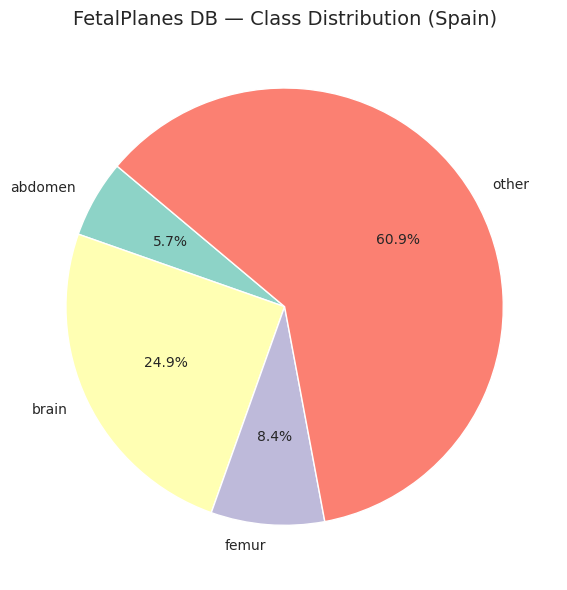

In [8]:
# Pie chart of full Spain distribution
total_counts = pivot["total"]
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(total_counts, labels=total_counts.index, autopct="%1.1f%%",
       startangle=140, colors=plt.cm.Set3.colors)
ax.set_title("FetalPlanes DB - Class Distribution (Spain)", fontsize=14)
plt.tight_layout()
plt.savefig("docs/spain_class_distribution.png", dpi=150)
plt.show()


## 2. Class Distribution - African Datasets

split    train   val  test
class                     
abdomen   69.0  31.0  25.0
brain     69.0  31.0  25.0
femur     69.0  31.0  25.0
other     33.0  17.0  25.0


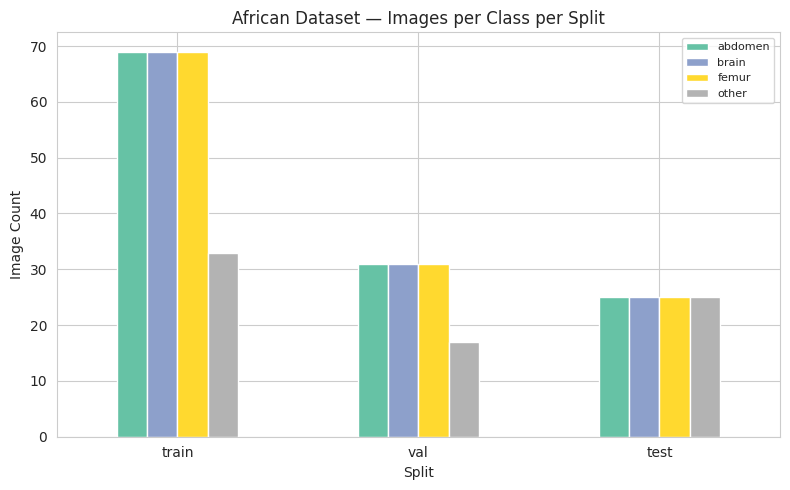

In [9]:
african_root = Path("data/african")
SPLITS = ["train", "val", "test"]

records_af = []
for split in SPLITS:
    for cls in CLASSES:
        d = african_root / split / cls
        if d.exists():
            n = len(list(d.glob("*.png")) + list(d.glob("*.jpg")))
            records_af.append({"split": split, "class": cls, "count": n})

df_af = pd.DataFrame(records_af)
pivot_af = df_af.pivot_table(index="class", columns="split", values="count", fill_value=0)

# Enforce consistent column order
pivot_af = pivot_af[["train", "val", "test"]]

print(pivot_af.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
pivot_af.T.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_title("African Dataset - Images per Class per Split")
ax.set_xlabel("Split")
ax.set_ylabel("Image Count")
ax.legend(loc="upper right", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("docs/african_class_distribution.png", dpi=150)
plt.show()

## 3. Sample Images - Spain vs. Africa (same class)

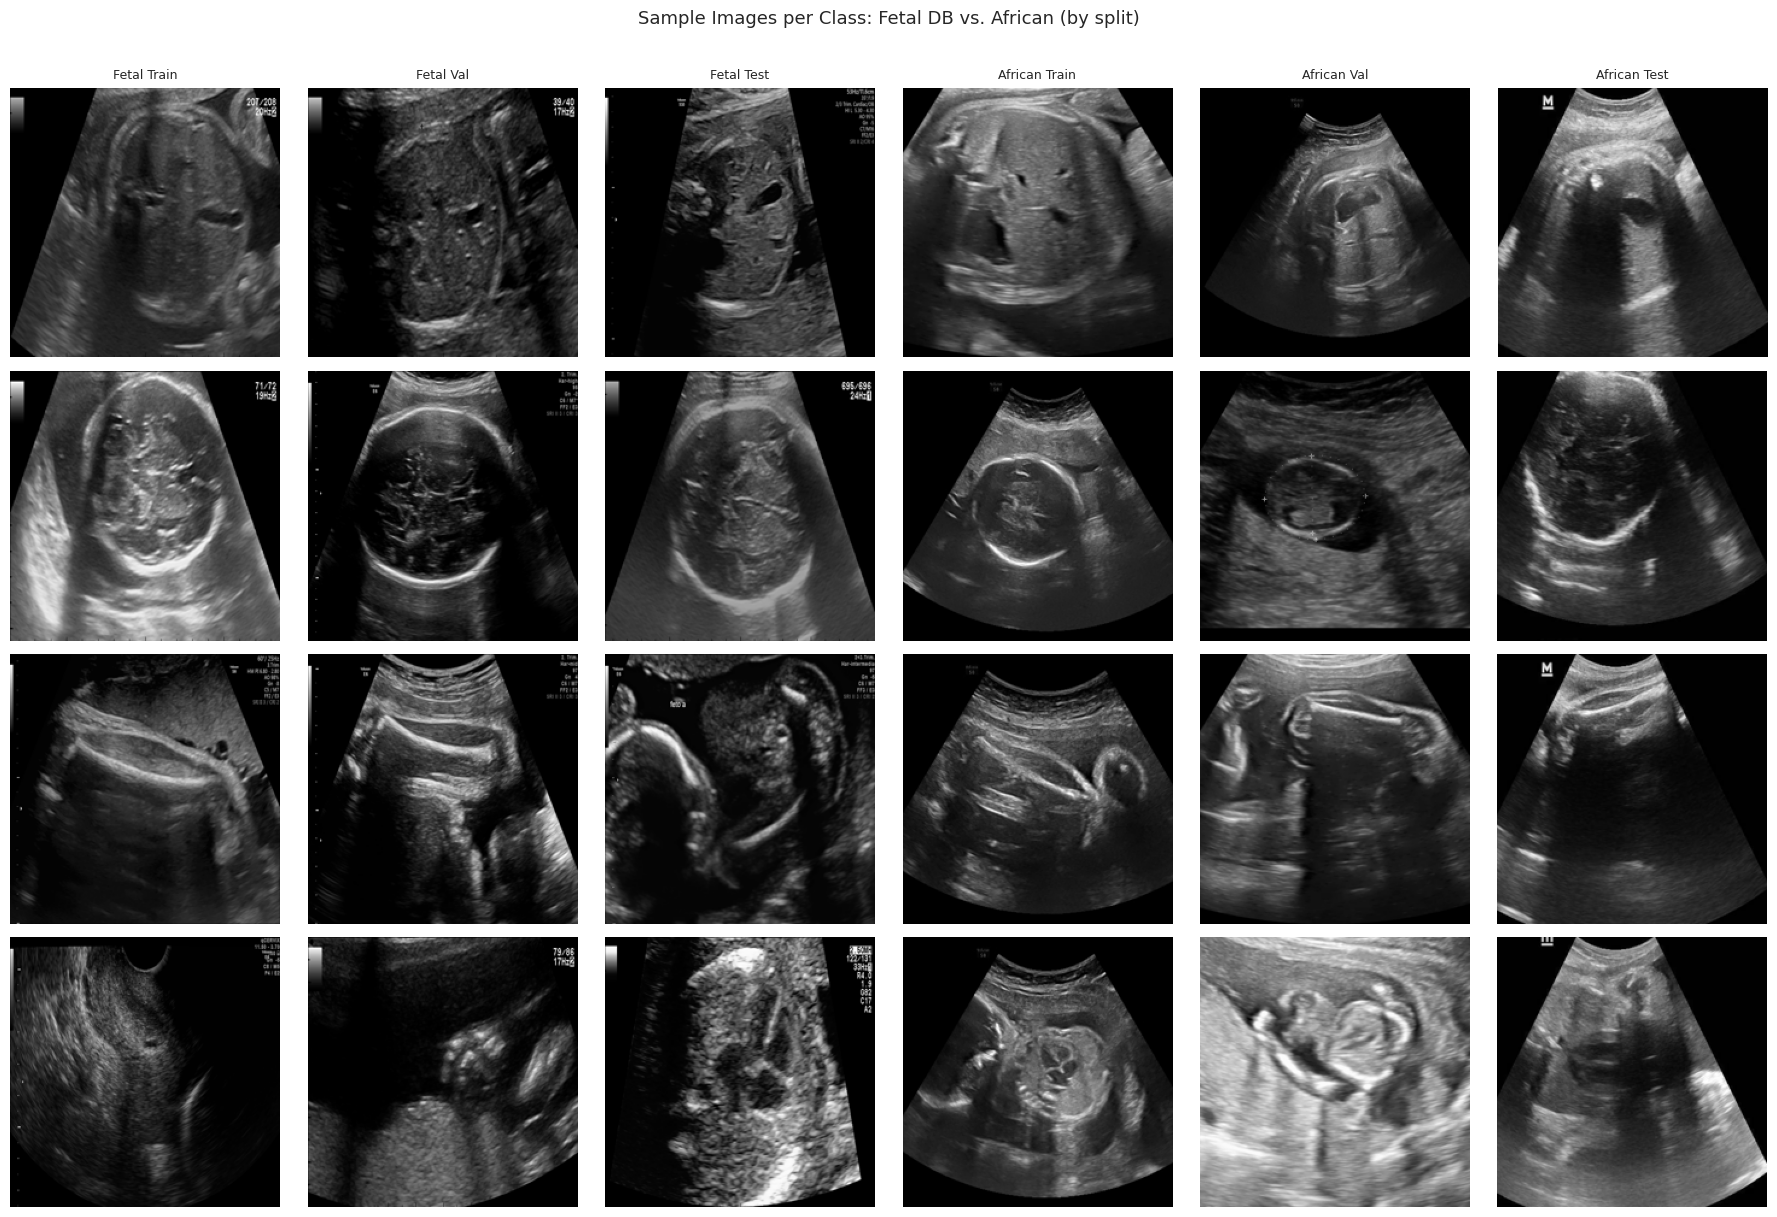

In [10]:
def load_sample_images(root, cls, n=3):
    d = root / cls
    if not d.exists():
        return []
    imgs = list(d.glob("*.png")) + list(d.glob("*.jpg"))
    return [np.array(Image.open(p).convert("RGB").resize((224, 224))) for p in imgs[:n]]

# Columns: fetal_db splits + african splits
DOMAINS = [
    ("Fetal Train",  spain_root  / "train"),
    ("Fetal Val",    spain_root  / "val"),
    ("Fetal Test",   spain_root  / "test"),
    ("African Train", african_root / "train"),
    ("African Val",   african_root / "val"),
    ("African Test",  african_root / "test"),
]

fig, axes = plt.subplots(len(CLASSES), len(DOMAINS), figsize=(3 * len(DOMAINS), 3 * len(CLASSES)))

for row, cls in enumerate(CLASSES):
    for col, (domain_name, domain_path) in enumerate(DOMAINS):
        ax = axes[row, col]
        d = domain_path / cls
        imgs = []
        if d.exists():
            files = list(d.glob("*.png")) + list(d.glob("*.jpg"))
            if files:
                imgs = [np.array(Image.open(files[0]).convert("RGB").resize((224, 224)))]

        if imgs:
            ax.imshow(imgs[0])
        else:
            ax.imshow(np.zeros((224, 224, 3), dtype=np.uint8))
            ax.text(112, 112, "N/A", ha="center", va="center", color="white", fontsize=8)

        if row == 0: ax.set_title(domain_name, fontsize=9)
        if col == 0: ax.set_ylabel(cls.replace("_", " "), fontsize=8, rotation=90, labelpad=4)
        ax.axis("off")

plt.suptitle("Sample Images per Class: Fetal DB vs. African (by split)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("docs/sample_images_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Image Quality Analysis

               mean_brightness  contrast  sharpness  snr_estimate
domain                                                           
African Test             63.80     58.78     405.34          5.76
African Train            56.07     39.51     296.65          5.62
African Val              57.28     40.49     298.64          5.77
Fetal Test               50.74     43.52     380.75          6.39
Fetal Train              45.91     40.24     465.50          6.28
Fetal Val                44.90     41.76     464.30          7.52


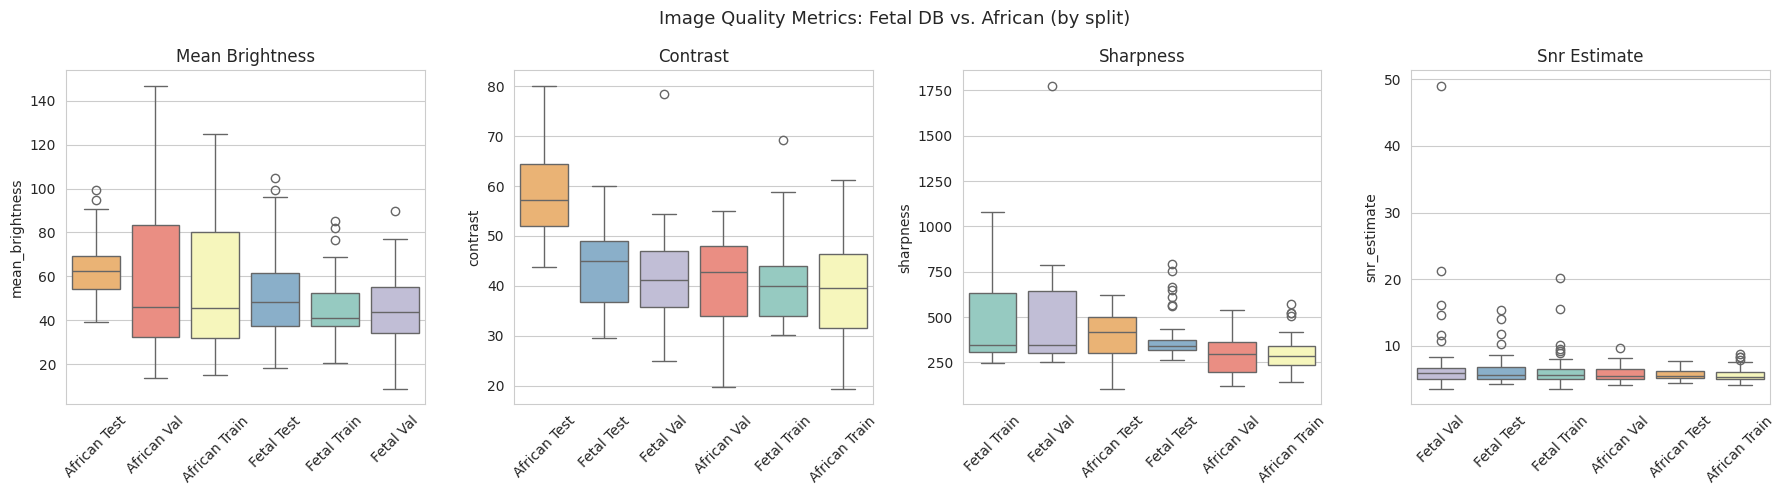

In [11]:
# Compute quality metrics for a sample of images from each domain
quality_records = []

def sample_quality(img_dir: Path, domain: str, n: int = 50):
    imgs = list(img_dir.rglob("*.png"))[:n]
    for p in imgs:
        arr = np.array(Image.open(p).convert("RGB"))
        q = compute_image_quality_score(arr)
        quality_records.append({"domain": domain, "path": str(p), **q})

# Sample from each split of both datasets
for split in SPLITS:
    sample_quality(spain_root  / split, f"Fetal {split.title()}")
    sample_quality(african_root / split, f"African {split.title()}")

df_quality = pd.DataFrame(quality_records)
print(df_quality.groupby("domain")[["mean_brightness", "contrast", "sharpness", "snr_estimate"]].mean().round(2))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics_q = ["mean_brightness", "contrast", "sharpness", "snr_estimate"]

for ax, m in zip(axes, metrics_q):
    order = df_quality.groupby("domain")[m].mean().sort_values(ascending=False).index
    # sns.boxplot(data=df_quality, x="domain", y=m, order=order, ax=ax, palette="Set3")
    sns.boxplot(data=df_quality, x="domain", y=m, order=order, ax=ax,
                hue="domain", palette="Set3", legend=False)
    ax.set_title(m.replace("_", " ").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Image Quality Metrics: Fetal DB vs. African (by split)", fontsize=13)
plt.tight_layout()
plt.savefig("docs/image_quality_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# CLAHE experiments

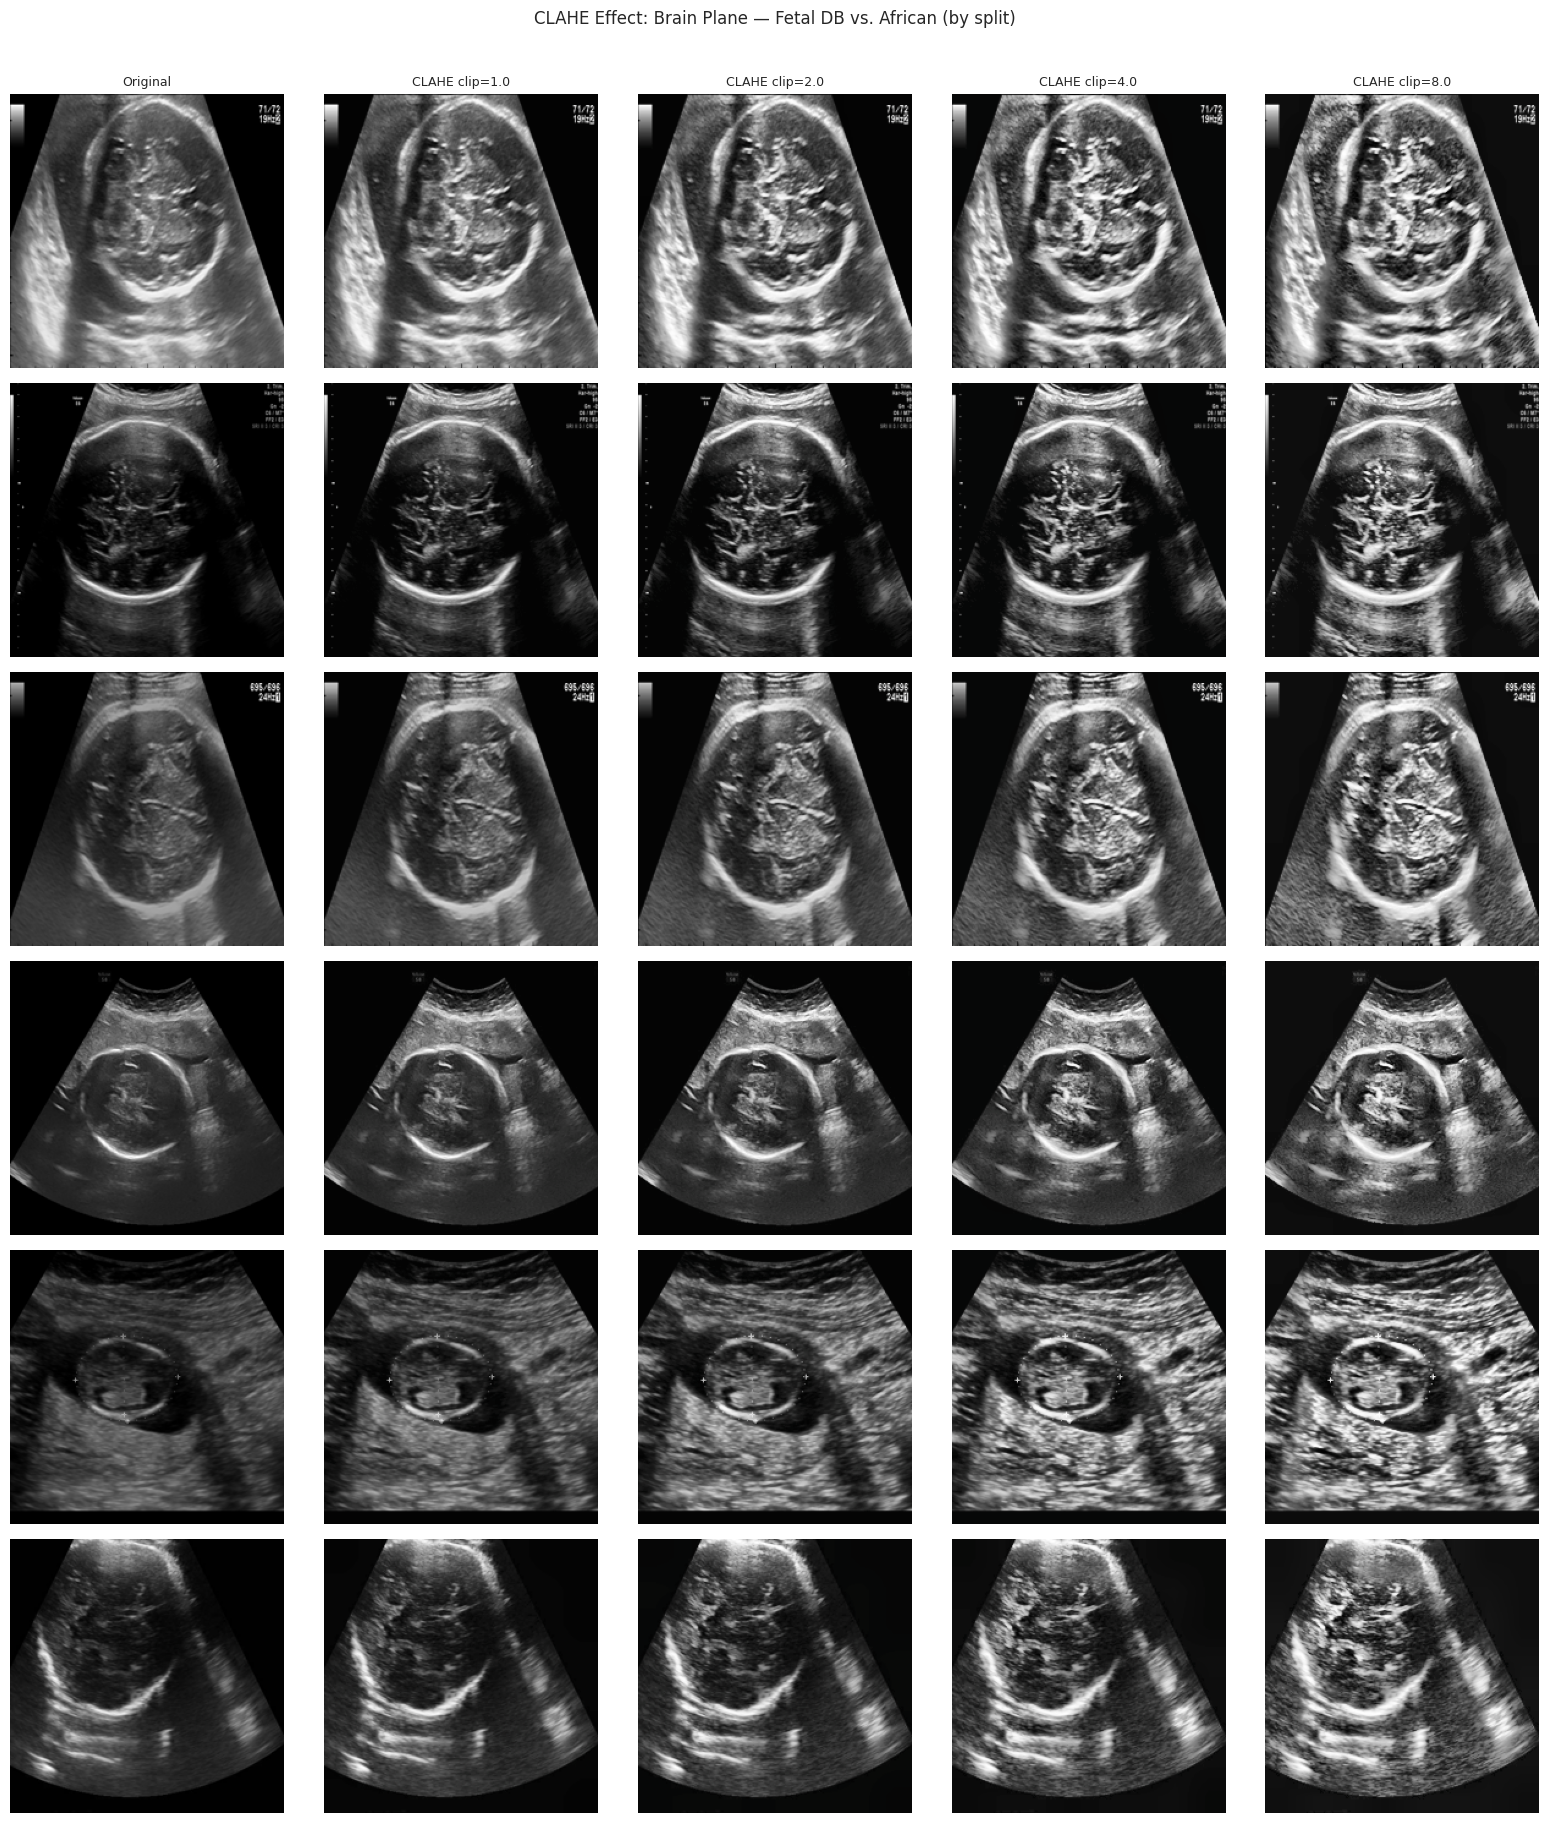

In [12]:
fetal_root   = Path("data/fetal_db")
african_root = Path("data/african")

def get_sample_image(root, cls="brain"):
    d = root / cls if (root / cls).exists() else root
    imgs = list(d.rglob("*.png"))
    if not imgs:
        return None
    return np.array(Image.open(imgs[0]).convert("RGB").resize((224, 224)))

# Test different CLAHE clip limits
clip_limits = [1.0, 2.0, 4.0, 8.0]

# Domains: one row per dataset split
domains = {
    "Fetal Train":   fetal_root   / "train",
    "Fetal Val":     fetal_root   / "val",
    "Fetal Test":    fetal_root   / "test",
    "African Train": african_root / "train",
    "African Val":   african_root / "val",
    "African Test":  african_root / "test",
}

fig, axes = plt.subplots(len(domains), len(clip_limits) + 1,
                          figsize=(16, 3 * len(domains)))

for row, (domain_name, root) in enumerate(domains.items()):
    img = get_sample_image(root, "brain")
    if img is None:
        for ax in axes[row]: ax.axis("off")
        axes[row, 0].text(112, 112, "N/A", ha="center", va="center", fontsize=8)
        continue

    # Original
    axes[row, 0].imshow(img)
    axes[row, 0].axis("off")
    axes[row, 0].set_ylabel(domain_name, fontsize=8)
    if row == 0: axes[row, 0].set_title("Original", fontsize=9)

    for col, clip in enumerate(clip_limits, start=1):
        clahe = CLAHEPreprocessor(clip_limit=clip)
        enhanced = np.array(clahe(Image.fromarray(img)))
        axes[row, col].imshow(enhanced)
        axes[row, col].axis("off")
        if row == 0: axes[row, col].set_title(f"CLAHE clip={clip}", fontsize=9)

plt.suptitle("CLAHE Effect: Brain Plane - Fetal DB vs. African (by split)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("docs/clahe_visual_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# CLAHE IMPACT

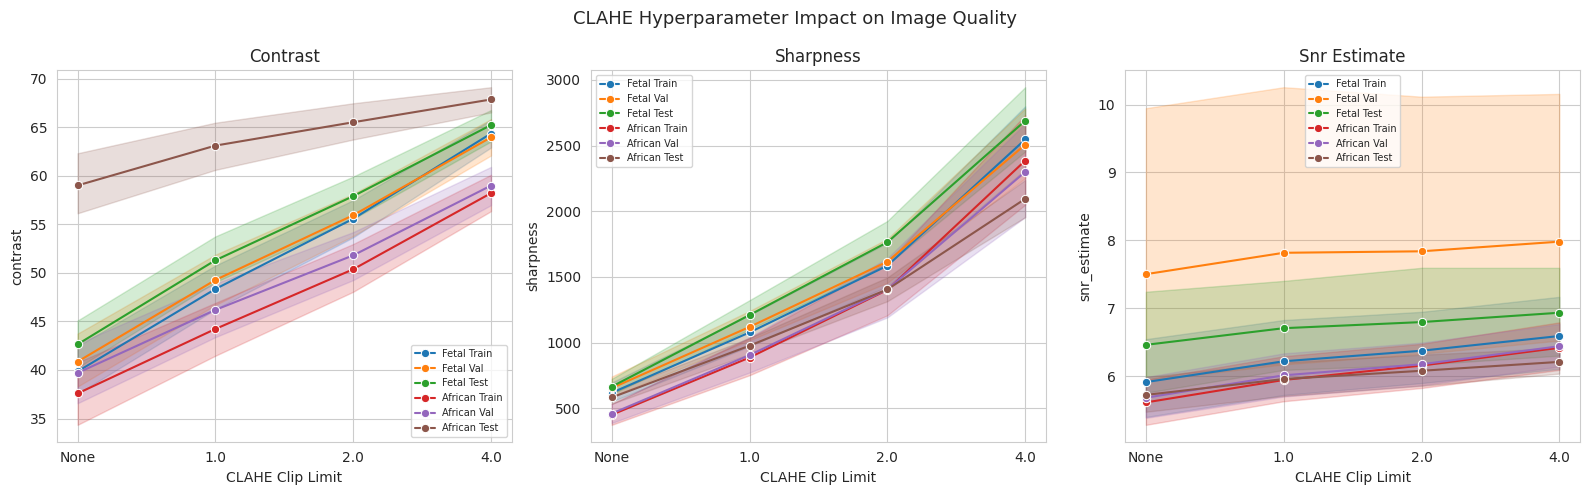

In [13]:
# Measure quality before/after CLAHE for each domain
results = []

domains = {
    "Fetal Train":   fetal_root   / "train",
    "Fetal Val":     fetal_root   / "val",
    "Fetal Test":    fetal_root   / "test",
    "African Train": african_root / "train",
    "African Val":   african_root / "val",
    "African Test":  african_root / "test",
}

for domain_name, root in domains.items():
    imgs = list(root.rglob("*.png"))[:40]
    for clip in [None, 1.0, 2.0, 4.0]:
        clahe = CLAHEPreprocessor(clip_limit=clip) if clip else None
        for p in imgs:
            arr = np.array(Image.open(p).convert("RGB").resize((224, 224)))
            if clahe:
                arr = np.array(clahe(Image.fromarray(arr)))
            q = compute_image_quality_score(arr)
            results.append({"domain": domain_name, "clip": str(clip or "None"), **q})

df_q = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["contrast", "sharpness", "snr_estimate"]):
    sns.lineplot(data=df_q, x="clip", y=metric, hue="domain",
                 marker="o", ax=ax, palette="tab10")
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("CLAHE Clip Limit")
    ax.legend(fontsize=7)

plt.suptitle("CLAHE Hyperparameter Impact on Image Quality", fontsize=13)
plt.tight_layout()
plt.savefig("docs/clahe_quality_metrics.png", dpi=150)
plt.show()

In [14]:
CONTRAST_THRESHOLD = 35  # grayscale std below which CLAHE is applied

def maybe_apply_clahe(arr: np.ndarray, clahe: CLAHEPreprocessor, threshold: float) -> tuple[np.ndarray, bool]:
    """Apply CLAHE only if image contrast is below threshold."""
    q = compute_image_quality_score(arr)
    if q["contrast"] < threshold:
        return np.array(clahe(Image.fromarray(arr))), True
    return arr, False

In [15]:
clahe = CLAHEPreprocessor(clip_limit=2.0)  # chosen from the clip-limit comparison above

for p in imgs:
    arr = np.array(Image.open(p).convert("RGB").resize((224, 224)))
    arr, was_enhanced = maybe_apply_clahe(arr, clahe, CONTRAST_THRESHOLD)

In [16]:
results = []
for domain_name, root in domains.items():
    imgs = []
    for cls in ["brain", "femur", "abdomen"]:
        cls_dir = root / cls
        if cls_dir.exists():
            imgs += list(cls_dir.glob("*.png"))
    imgs = imgs[:40]

    enhanced_count = 0
    for p in imgs:
        arr = np.array(Image.open(p).convert("RGB").resize((224, 224)))
        _, was_enhanced = maybe_apply_clahe(arr, clahe, CONTRAST_THRESHOLD)
        if was_enhanced:
            enhanced_count += 1

    print(f"{domain_name:20s}: {enhanced_count}/{len(imgs)} images enhanced")

Fetal Train         : 9/40 images enhanced
Fetal Val           : 6/40 images enhanced
Fetal Test          : 1/40 images enhanced
African Train       : 19/40 images enhanced
African Val         : 17/40 images enhanced
African Test        : 2/40 images enhanced


In [17]:
for domain_name, root in [("African Test", african_root / "test"), 
                           ("Fetal Test",   fetal_root  / "test")]:
    imgs = []
    for cls in ["brain", "femur", "abdomen"]:
        cls_dir = root / cls
        if cls_dir.exists():
            imgs += list(cls_dir.glob("*.png"))
    
    enhanced_count = sum(
        1 for p in imgs
        if compute_image_quality_score(
            np.array(Image.open(p).convert("RGB").resize((224, 224)))
        )["contrast"] < CONTRAST_THRESHOLD
    )
    print(f"{domain_name:20s}: {enhanced_count}/{len(imgs)} images enhanced")

African Test        : 2/75 images enhanced
Fetal Test          : 398/2354 images enhanced


## SELECTIVE CLAHE

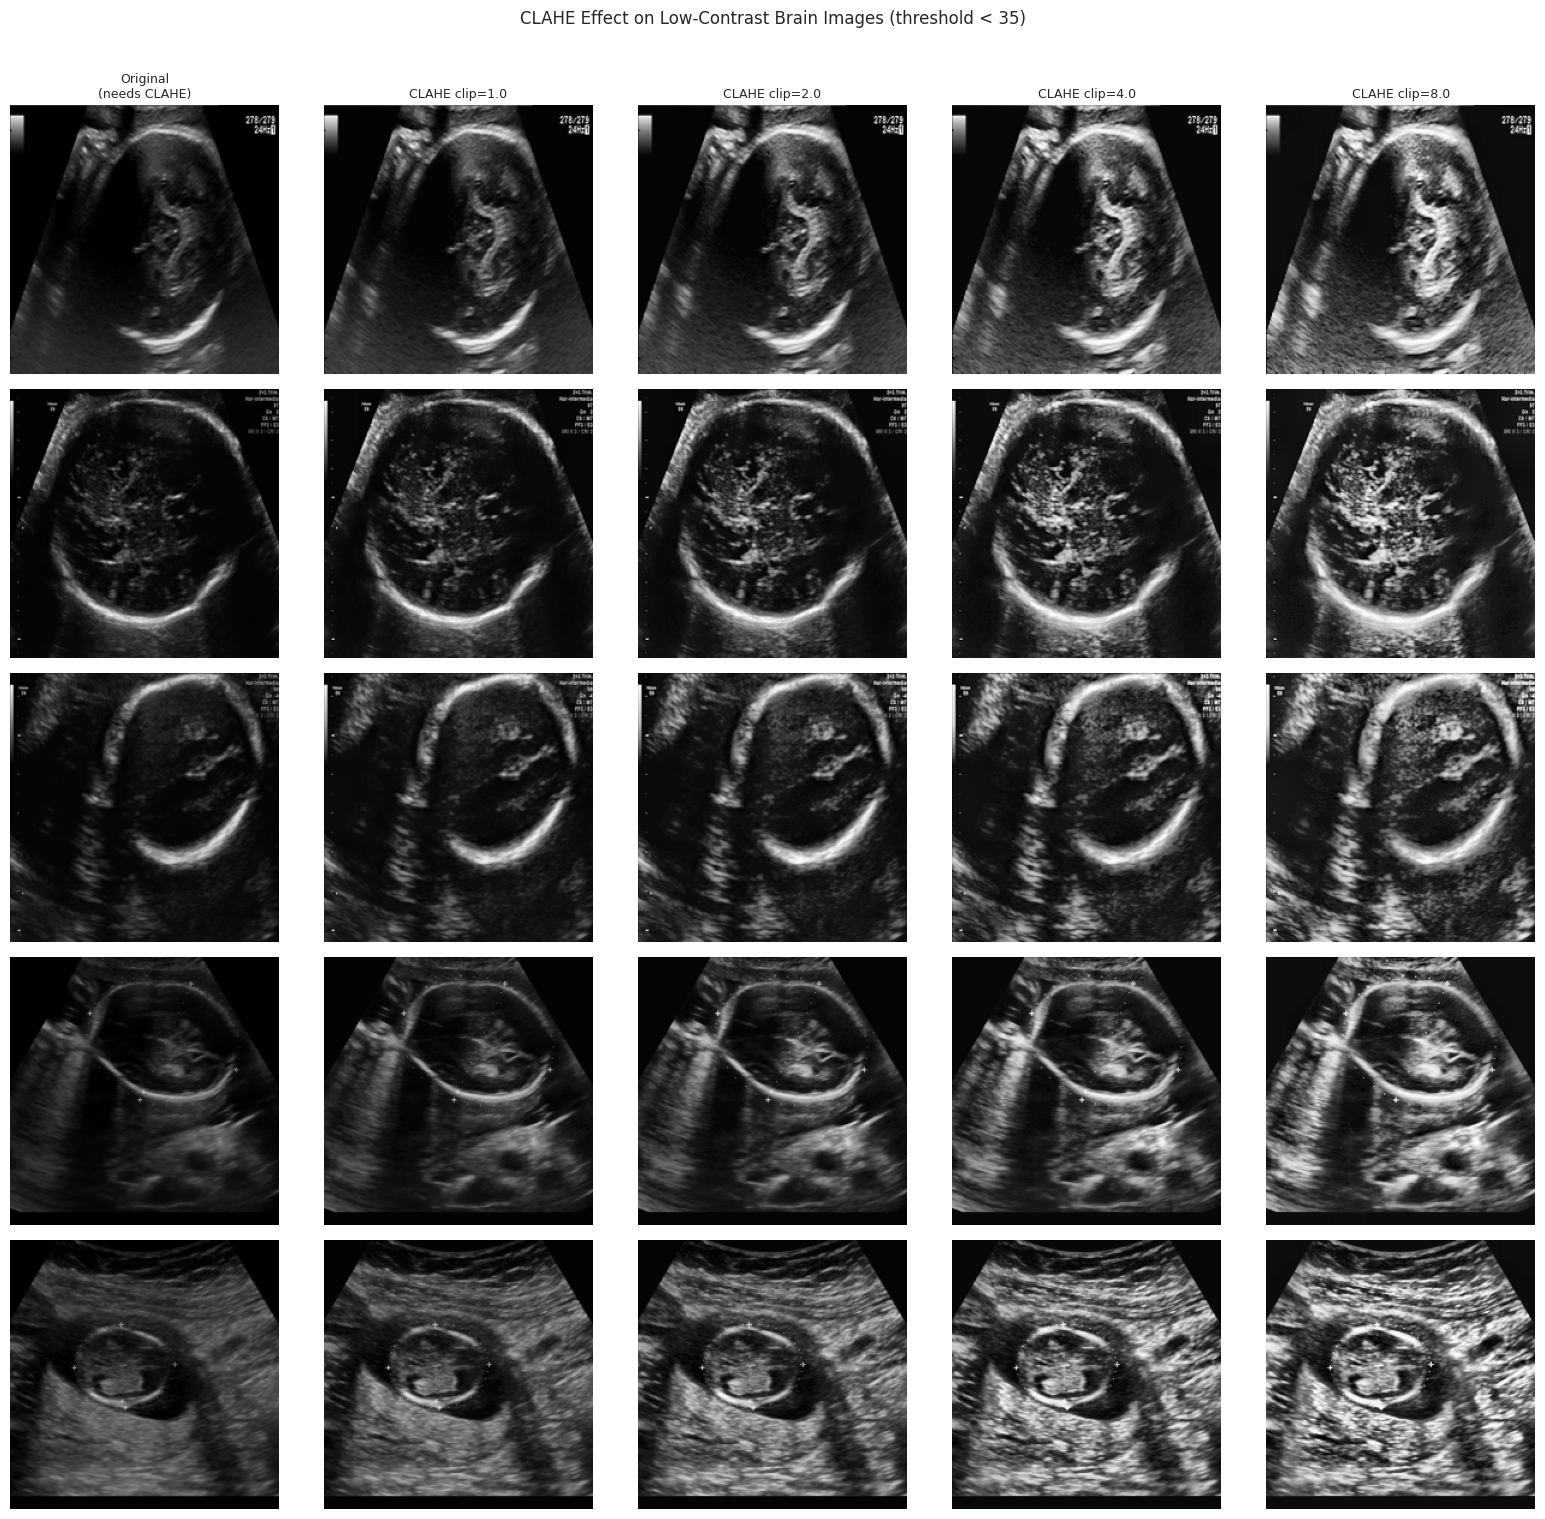

In [18]:
fetal_root   = Path("data/fetal_db")
african_root = Path("data/african")

def get_low_contrast_image(root, cls="brain", threshold=CONTRAST_THRESHOLD):
    """Find the first image in cls folder that actually needs CLAHE."""
    d = root / cls if (root / cls).exists() else root
    imgs = list(d.rglob("*.png"))
    for p in imgs:
        arr = np.array(Image.open(p).convert("RGB").resize((224, 224)))
        q = compute_image_quality_score(arr)
        if q["contrast"] < threshold:
            return arr
    return None  # no low-contrast image found in sample

# Test different CLAHE clip limits
clip_limits = [1.0, 2.0, 4.0, 8.0]

domains = {
    "Fetal Train":   fetal_root   / "train",
    "Fetal Val":     fetal_root   / "val",
    "Fetal Test":    fetal_root   / "test",
    "African Train": african_root / "train",
    "African Val":   african_root / "val",
    "African Test":  african_root / "test",
}

# Pre-fetch only low-contrast images - skip domains with none
domain_imgs = {
    name: get_low_contrast_image(root, "brain")
    for name, root in domains.items()
}
domain_imgs = {name: img for name, img in domain_imgs.items() if img is not None}

if not domain_imgs:
    print("No low-contrast images found - try raising CONTRAST_THRESHOLD.")
else:
    fig, axes = plt.subplots(len(domain_imgs), len(clip_limits) + 1,
                              figsize=(16, 3 * len(domain_imgs)))

    # Ensure axes is always 2D even with one row
    if len(domain_imgs) == 1:
        axes = axes[np.newaxis, :]

    for row, (domain_name, img) in enumerate(domain_imgs.items()):
        q = compute_image_quality_score(img)

        # Original
        axes[row, 0].imshow(img)
        axes[row, 0].axis("off")
        axes[row, 0].set_ylabel(domain_name, fontsize=8)
        axes[row, 0].set_xlabel(f"contrast={q['contrast']:.1f}", fontsize=7)
        if row == 0: axes[row, 0].set_title("Original\n(needs CLAHE)", fontsize=9)

        for col, clip in enumerate(clip_limits, start=1):
            clahe = CLAHEPreprocessor(clip_limit=clip)
            enhanced = np.array(clahe(Image.fromarray(img)))
            q_enh = compute_image_quality_score(enhanced)
            axes[row, col].imshow(enhanced)
            axes[row, col].axis("off")
            axes[row, col].set_xlabel(f"contrast={q_enh['contrast']:.1f}", fontsize=7)
            if row == 0: axes[row, col].set_title(f"CLAHE clip={clip}", fontsize=9)

    plt.suptitle(f"CLAHE Effect on Low-Contrast Brain Images (threshold < {CONTRAST_THRESHOLD})",
                 fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig("docs/clahe_visual_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

  Fetal Train         : 40 low-contrast images sampled
  Fetal Val           : 40 low-contrast images sampled
  Fetal Test          : 40 low-contrast images sampled
  African Train       : 40 low-contrast images sampled
  African Val         : 35 low-contrast images sampled
  African Test        : 2 low-contrast images sampled


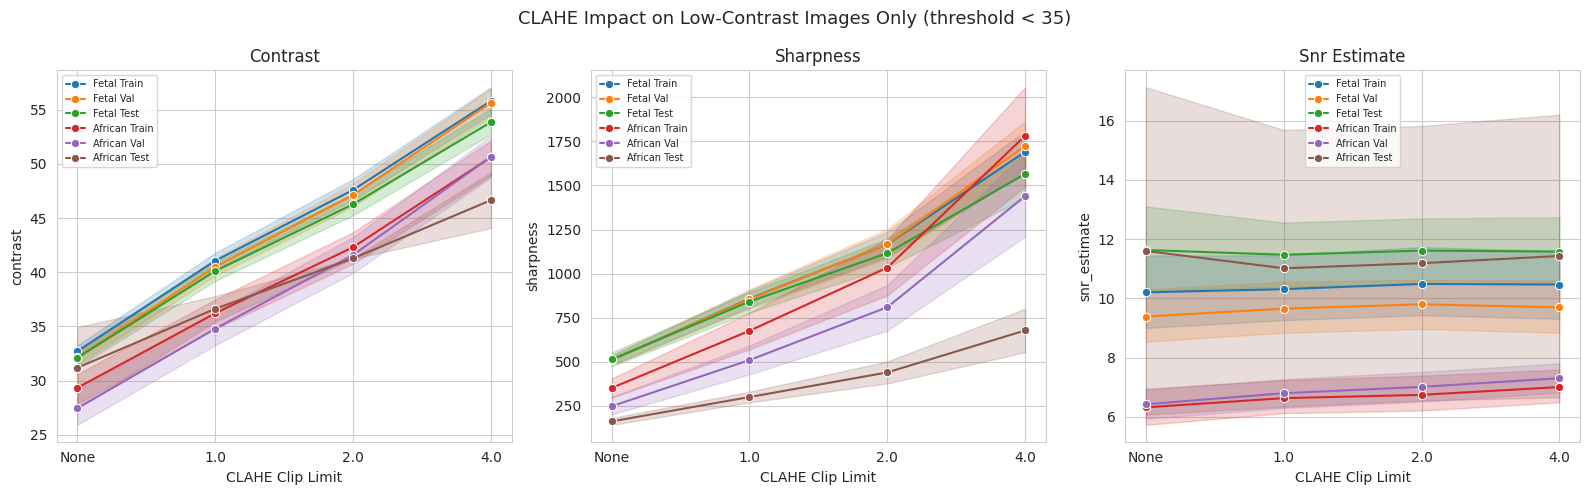

In [19]:
# Measure quality before/after CLAHE - only on images that need it
results = []

domains = {
    "Fetal Train":   fetal_root   / "train",
    "Fetal Val":     fetal_root   / "val",
    "Fetal Test":    fetal_root   / "test",
    "African Train": african_root / "train",
    "African Val":   african_root / "val",
    "African Test":  african_root / "test",
}

for domain_name, root in domains.items():
    # Only sample from standard plane classes, skip "other"
    imgs = []
    for cls in ["brain", "femur", "abdomen"]:
        cls_dir = root / cls
        if cls_dir.exists():
            imgs += list(cls_dir.glob("*.png"))

    # Filter to only low-contrast images
    low_contrast_imgs = []
    for p in imgs:
        arr = np.array(Image.open(p).convert("RGB").resize((224, 224)))
        q = compute_image_quality_score(arr)
        if q["contrast"] < CONTRAST_THRESHOLD:
            low_contrast_imgs.append((p, arr))
        if len(low_contrast_imgs) >= 40:
            break

    if not low_contrast_imgs:
        print(f"  [SKIP] {domain_name} - no low-contrast images found")
        continue

    print(f"  {domain_name:20s}: {len(low_contrast_imgs)} low-contrast images sampled")

    for clip in [None, 1.0, 2.0, 4.0]:
        clahe = CLAHEPreprocessor(clip_limit=clip) if clip else None
        for _, arr in low_contrast_imgs:
            out = np.array(clahe(Image.fromarray(arr))) if clahe else arr
            q = compute_image_quality_score(out)
            results.append({"domain": domain_name, "clip": str(clip or "None"), **q})

df_q = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["contrast", "sharpness", "snr_estimate"]):
    sns.lineplot(data=df_q, x="clip", y=metric, hue="domain",
                 marker="o", ax=ax, palette="tab10")
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("CLAHE Clip Limit")
    ax.legend(fontsize=7)

plt.suptitle(f"CLAHE Impact on Low-Contrast Images Only (threshold < {CONTRAST_THRESHOLD})",
             fontsize=13)
plt.tight_layout()
plt.savefig("docs/clahe_quality_metrics.png", dpi=150)
plt.show()

# CLAHE Impact on model performance

In [20]:
# !pip install torch==2.0.1 torchvision==0.15.2 --index-url https://download.pytorch.org/whl/cu116 -q

In [21]:
# Run quick training experiment: baseline vs CLAHE on Fetal DB
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # force CPU
print("Training WITHOUT CLAHE (baseline)...")
!python scripts/train.py \
    --experiment baseline_fetal \
    --tracker none \
    --seed 42

Training WITHOUT CLAHE (baseline)...
12:53:59 | INFO     | train | Running experiment  : baseline_fetal
12:53:59 | INFO     | train | Description         : Train and evaluate on Fetal DB only (pre-split train/val/test)
/kaggle/working/OBS_Ultrasound_standard_plane_classification/modelling/src/data/augmentation.py:40: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
/kaggle/working/OBS_Ultrasound_standard_plane_classification/modelling/src/data/augmentation.py:42: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(
12:53:59 | INFO     | train | Dataset sizes - train: 5121  val: 2008
model.safetensors: 100%|###################| 21.4M/21.4M [00:01<00:00, 20.8MB/s]
12:54:00 | INFO     | train | Parameters - total: 4,012,672  trainable: 4,012,672
12:55:20 | INFO     | src.training.trainer | Epoch   1/50 | train_loss=1.3674 | val_loss=0.5897 | val_acc

In [22]:
print("\nTraining WITH CLAHE...")
!python scripts/train.py \
    --experiment baseline_fetal_clahe \
    --tracker none \
    --seed 42


Training WITH CLAHE...
13:09:58 | INFO     | train | Running experiment  : baseline_fetal_clahe
13:09:58 | INFO     | train | Description         : Same as baseline_fetal but with conditional CLAHE preprocessing
/kaggle/working/OBS_Ultrasound_standard_plane_classification/modelling/src/data/augmentation.py:40: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
/kaggle/working/OBS_Ultrasound_standard_plane_classification/modelling/src/data/augmentation.py:42: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(
13:09:58 | INFO     | train | Dataset sizes - train: 5121  val: 2008
13:09:58 | INFO     | train | Parameters - total: 4,012,672  trainable: 4,012,672
13:12:07 | INFO     | src.training.trainer | Epoch   1/50 | train_loss=1.3190 | val_loss=0.6365 | val_acc=0.8785 | val_auc=0.0000 | 128.6s
13:13:55 | INFO     | src.training.trainer | Epoch   

In [27]:
# Quick zero-shot evaluation on African test set (Malawi): no CLAHE vs CLAHE
print("Zero-shot eval WITHOUT CLAHE on African test set:")
!python scripts/evaluate.py \
    --checkpoint checkpoints/baseline_fetal/best_auc.pt \
    --test_data african_test \
    --output results/zero_shot_no_clahe.json

print("\nZero-shot eval WITH CLAHE:")
!python scripts/evaluate.py \
    --checkpoint checkpoints/baseline_fetal_clahe/best_auc.pt \
    --test_data african_test \
    --use_clahe \
    --output results/zero_shot_clahe.json

Zero-shot eval WITHOUT CLAHE on African test set:
13:58:25 | INFO     | evaluate | Loaded efficientnet_b0 from checkpoints/baseline_fetal/best_auc.pt
13:58:25 | INFO     | evaluate | African test set: 100 images
13:58:25 | INFO     | evaluate | 
Evaluating on: african_test
13:58:26 | INFO     | evaluate |   Accuracy : 0.6900
13:58:26 | INFO     | evaluate |   AUC      : 0.9010
13:58:26 | INFO     | evaluate |   F1 macro : 0.6721
              precision    recall  f1-score   support

     abdomen       1.00      0.52      0.68        25
       brain       1.00      1.00      1.00        25
       femur       1.00      0.24      0.39        25
       other       0.45      1.00      0.62        25

    accuracy                           0.69       100
   macro avg       0.86      0.69      0.67       100
weighted avg       0.86      0.69      0.67       100

13:58:26 | INFO     | evaluate | Results saved to results/zero_shot_no_clahe.json

Zero-shot eval WITH CLAHE:
13:58:34 | INFO     | 

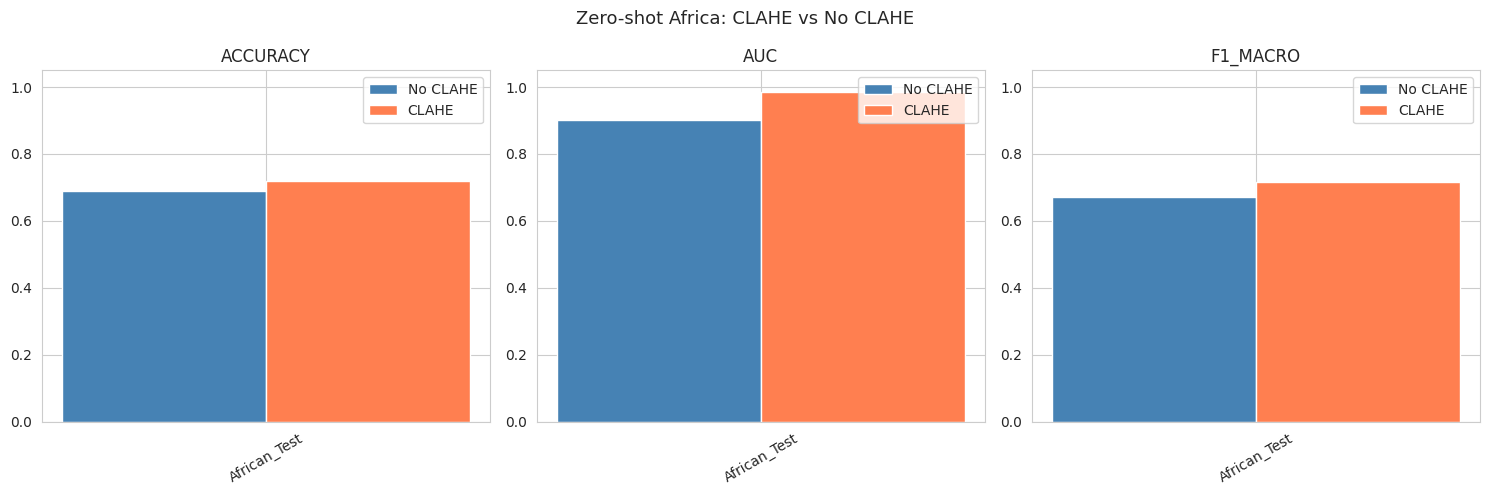

In [28]:
import json

def load_results(path):
    with open(path) as f:
        return json.load(f)

r_no_clahe = load_results("results/zero_shot_no_clahe.json")
r_clahe    = load_results("results/zero_shot_clahe.json")

countries = [c for c in r_no_clahe.keys() if c != "fps"]
metrics   = ["accuracy", "auc", "f1_macro"]

fig, axes = plt.subplots(1, len(metrics), figsize=(15, 5))
for ax, m in zip(axes, metrics):
    vals_no   = [r_no_clahe.get(c, {}).get(m, 0) for c in countries]
    vals_cl   = [r_clahe.get(c, {}).get(m, 0) for c in countries]
    x = range(len(countries))
    ax.bar([xi - 0.2 for xi in x], vals_no, width=0.4, label="No CLAHE", color="steelblue")
    ax.bar([xi + 0.2 for xi in x], vals_cl, width=0.4, label="CLAHE",    color="coral")
    ax.set_xticks(list(x)); ax.set_xticklabels([c.title() for c in countries], rotation=30)
    ax.set_title(m.upper()); ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle("Zero-shot Africa: CLAHE vs No CLAHE", fontsize=13)
plt.tight_layout()
plt.savefig("docs/clahe_performance_comparison.png", dpi=150)
plt.show()
